In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

In [64]:
def split_levels(x):
    if ':' in x:
        l1, l2 = x.split(':', 1)
        return pd.Series([l1.strip(), l2.strip()])
    else:
        return pd.Series([x.strip(), None])

def two_level_barh(df, col, xlabel=None, ylabel=None):

    df[f"M_{col}"] = df[col].apply(lambda x: x.split(", "))

    exploded = df[f"M_{col}"].explode()
    exploded = exploded.apply(split_levels)
    exploded.columns = ['Level1', 'Level2']
    exploded['Level2'] = exploded['Level2'].fillna('Absent')

    counts = exploded.groupby(['Level1', 'Level2']).size().unstack(fill_value=0)
    totals = counts.sum(axis=1)
    counts = counts.loc[totals.sort_values(ascending=True).index]

    counts.plot(
        kind='barh',
        stacked=True,
    )
    if xlabel is not None:
        plt.xlabel(xlabel)
    if ylabel is not None:
        plt.ylabel(ylabel)

In [3]:
# read and process dataset

# path = r"data\src\conflated_database___2026_03_31__11_14_35.xlsx - TextReading_Included.csv"
# df = pd.read_csv(path, usecols={"topic": str, "Title": str, "Year": int, "Source": str})

path = r"data\src\conflated_database___2026_03_31__11_14_35.xlsx"

df = pd.read_excel(path, sheet_name="TextReading_Included")

df = df[df.topic.notna()]
df.reset_index(drop=True, inplace=True)

df.topic = df.topic.apply(lambda x: x.split(", "))
df.Year = df.Year.astype(int)
df

,topic,Detailed GP,Title,Year,Source,Unnamed: 5,Pre processing outside generative model,Core Generative Paradigm,Dataset,Conditioning Regimes,...,Post processing outside generative model,Ultimate Output elements,Generalizability,User Studies,AF: Human-likeness,AF: Alignment-to-input,AF: Normative compliance,AF: Intrinsic,COMBINED,Ablation study (none if empty)
0,"[Model, Dataset, Evaluation]",Discriminators,Complex layout generation for large-scale floo...,2025,Scopus,NaN,Retriever: graph,Discriminative,"RPLAN, P-PLAN",all,...,"Geometry alignment, Opening placement",room function and contour,Absent,Absent,Pixel-level accuracy?,Absent,Absent,"RAI (Room Accessibility Index), Space Property...",NaN,yes
1,"[Model, Dataset]",NaN,Automated building layout generation using dee...,2023,Scopus,NaN,"Retriever: graph, Modifier: graph",Discriminative,GeLayout,all,...,Absent,walls,Absent,Intrinsic evaluation,"IoU, mIoU, Pixel-level accuracy?",Absent,Absent,Absent,NaN,NaN
2,[Model],NaN,FLNet: Graph Constrained Floor Layout Generation,2022,Scopus,NaN,Absent,Discriminative,RPLAN,all,...,Absent,"room function and contour, walls, entrance doo...",Absent,Realism,"FID (Quality), IoU",Absent,Absent,Absent,NaN,NaN
3,[Model],NaN,Skip-Connected Neural Networks with Layout Gra...,2023,arXiv,NaN,Absent,Discriminative,MSD,all,...,Absent,"room function and contour, walls",Absent,Absent,IoU (CVAAD),Absent,Absent,Absent,NaN,NaN
4,[Model],Discriminators (Stacked),FlexPlan: High-flexibility interactive floorpl...,2025,Scopus,NaN,Retriever: floorplan,Discriminative,RPLAN,all,...,"Geometry alignment, Opening placement","room function and contour, walls, interior doo...",external validation: new geometry,Intrinsic evaluation,FID (Similarity),Absent,Absent,Absent,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,[Dataset],NaN,MSD: A Benchmark Dataset for Floor Plan Genera...,2025,Scopus,NaN,Absent,Multiple Models,MSD,Multiple Models,...,Multiple Models,Multiple Models,Absent,Absent,"Mean IoU, Graph Compatibility",Absent,Absent,Absent,NaN,yes
68,"[Dataset, Evaluation]",NaN,The impact of architecturally qualified data i...,2024,Scopus,NaN,Absent,Multiple Models,"RPLAN, PUBLICPLAN",Multiple Models,...,Multiple Models,Multiple Models,Absent,"Realism, Ranking",Absent,Absent,Absent,Absent,NaN,NaN
69,[Evaluation],NaN,The Possibilities of Text-to-Image Tools for t...,2024,Scopus,NaN,Absent,Diffusion,Custom,all,...,Absent,"room function and contour, walls, interior doo...",Absent,Absent,Absent,Absent,Absent,Absent,NaN,NaN
70,[Evaluation],NaN,Quality assessment of residential layout desig...,2024,Scopus,NaN,Absent,GAN,RPLAN,all,...,Absent,"room function and contour, walls, interior doo...",Absent,Absent,"U test (room size proportions), U test (Visual...",Absent,Absent,Percent of isolated rooms,NaN,NaN


# RESULTS

### QUANTITY

In [5]:
# Figure: papers per Year

counts = df.groupby(['Year', 'Source']).size().unstack(fill_value=0)
counts = counts.sort_index()
counts

Source,Scopus,arXiv
Year,,
2019,1,0
2020,4,0
2021,1,0
2022,7,0
2023,8,4
2024,17,4
2025,24,2


<Axes: xlabel='Year', ylabel='# papers'>

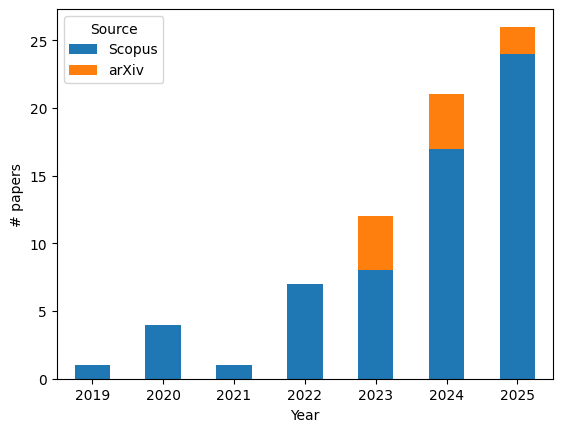

In [6]:
counts.plot(
    kind='bar',
    stacked=True,
    rot=0,
    ylabel="# papers"
)

In [7]:
# Novelty

df.topic.value_counts().sort_index()

topic
[Dataset]                        1
[Dataset, Evaluation]            1
[Evaluation]                     5
[Model]                         54
[Model, Dataset]                 7
[Model, Dataset, Evaluation]     3
[Model, Evaluation]              1
Name: count, dtype: int64

### MODEL

In [54]:
df_model = df[df.topic.apply(lambda x: "Model" in x)]

Text(0, 0.5, 'ML model')

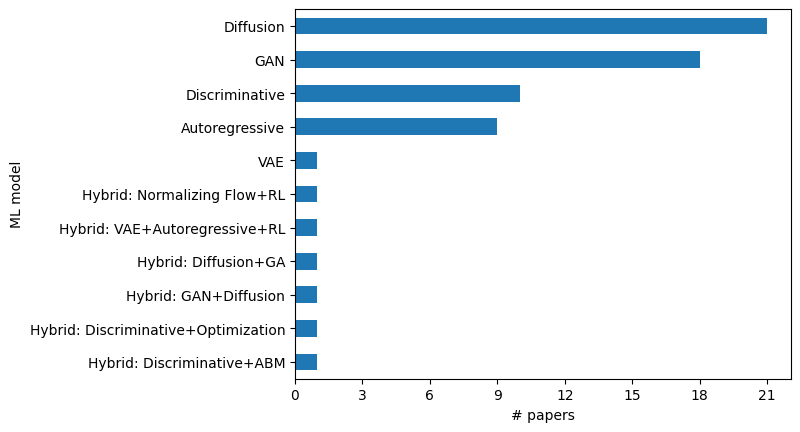

In [60]:
ax = df_model["Core Generative Paradigm"].value_counts(ascending=True).plot(kind="barh")
# ax.grid(axis="x")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("# papers")
ax.set_ylabel("ML model")


#### Discriminative vs Generative

In [24]:
df_model["Model Group"] = df_model["Core Generative Paradigm"].apply(lambda x: "Discriminative" if "Discriminative" in x else "Generative")
df_model["Model Group"].value_counts()

Model Group
Generative        53
Discriminative    12
Name: count, dtype: int64

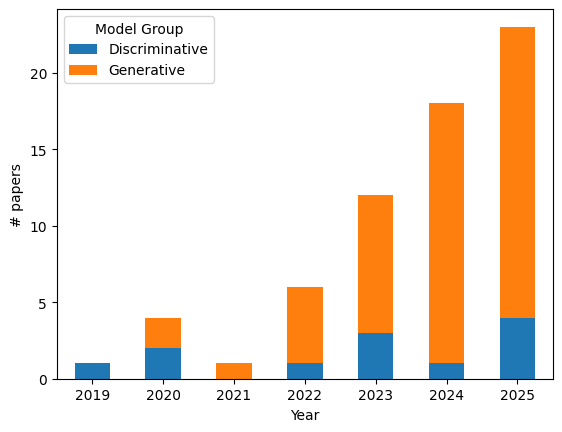

In [25]:
group_counts = df_model.groupby(['Year', 'Model Group']).size().unstack(fill_value=0)
group_counts = group_counts.sort_index()
group_counts

ax = group_counts.plot(
    kind='bar',
    stacked=True,
    rot=0,
    ylabel="# papers"
)
# ax.grid(axis="y")

#### Discriminative Hybrid vs Generative Hybrid

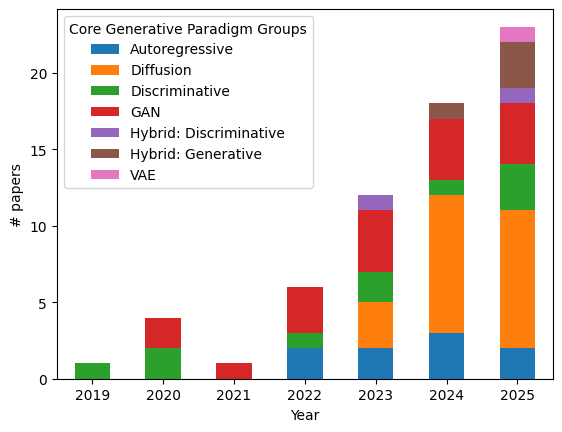

In [49]:
df_model["Core Generative Paradigm Groups"] = \
df_model["Core Generative Paradigm"].apply(lambda x: 
    "Hybrid: Discriminative" if ("Hybrid" in x and "Discriminative" in x) else 
    (
        "Hybrid: Generative" if "Hybrid" in x else x
    )
)

model_counts = df_model.groupby(['Year', 'Core Generative Paradigm Groups']).size().unstack(fill_value=0)
model_counts = model_counts.sort_index()

ax = model_counts.plot(
    kind='bar',
    stacked=True,
    rot=0,
    ylabel="# papers"
)

In [50]:
# ax = df_model["Core Generative Paradigm Groups"].value_counts(ascending=True).plot(
#     kind="barh",
# )
# ax.grid(axis="x")
# ax.xaxis.set_major_locator(MaxNLocator(integer=True))

In [51]:
# df_hybrid = df_model[df_model["Core Generative Paradigm Groups"].isin(["Hybrid: Discriminative", "Hybrid: Generative"])]
# df_hybrid["Core Generative Paradigm"].value_counts().plot(kind="pie")

### POST PROCESSING

<Axes: xlabel='# papers', ylabel='Post-processing technique'>

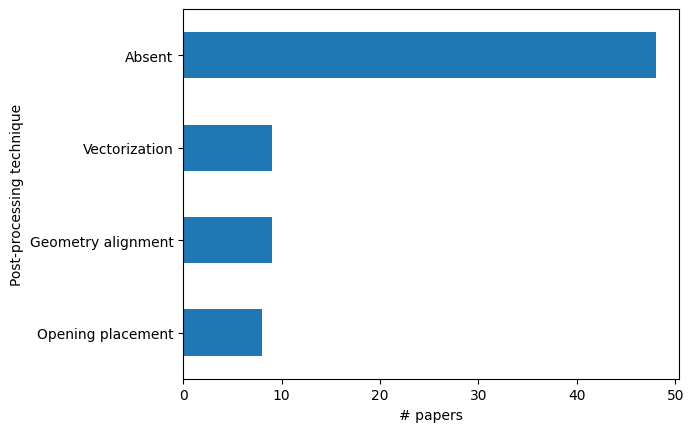

In [62]:
df_model["postprocessing"] = df_model["Post processing outside generative model"].apply(lambda x: x.split(", "))
df_model["postprocessing"].explode().value_counts(ascending=True).plot(kind="barh", xlabel="# papers", ylabel="Post-processing technique")

### PRE PROCESSING

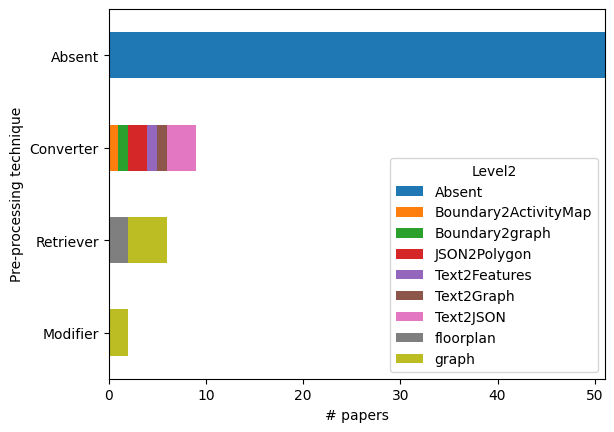

In [65]:
# df_model["preprocessing"] = df_model["Pre processing outside generative model"].apply(lambda x: x.split(", "))
# df_model["preprocessing"].explode().value_counts(ascending=True).plot(kind="pie")

two_level_barh(df_model, "Pre processing outside generative model", xlabel="# papers", ylabel="Pre-processing technique")

In [ ]:
///

### DATASET

<Axes: xlabel='# papers', ylabel='dataset'>

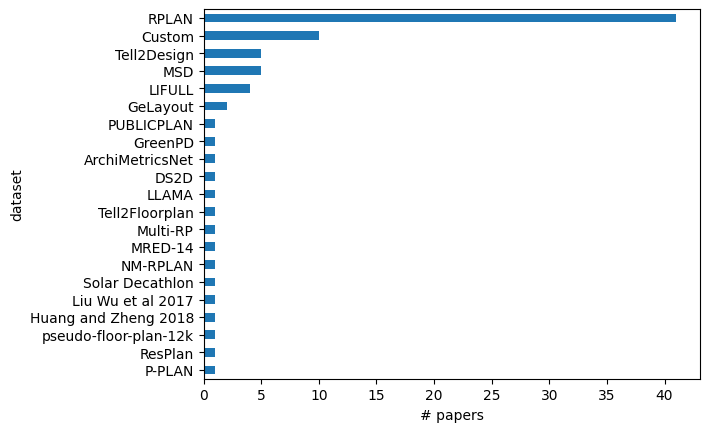

In [15]:
df["dataset"] = df["Dataset"].apply(lambda x: x.split(", "))

dataset_exploded = df.explode("dataset")
dataset_exploded["dataset"].value_counts(ascending=True).plot(kind="barh", xlabel="# papers")

<Axes: xlabel='# papers', ylabel='dataset_grouped'>

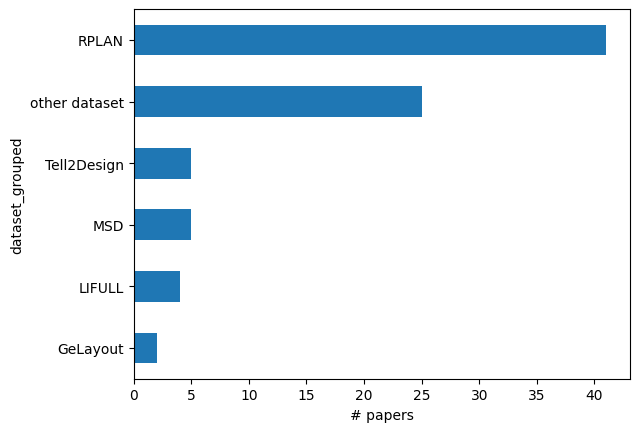

In [16]:
dataset_exploded["dataset_grouped"] = dataset_exploded.dataset.apply(lambda x: x if x in ["LIFULL", "RPLAN", "GeLayout", "MSD", "Tell2Design"] else "other dataset")
dataset_exploded["dataset_grouped"].value_counts(ascending=True).plot(kind="barh", xlabel="# papers")

In [17]:
unique_ds_list = [
    d for d in dataset_exploded["dataset"].unique() if d not in ["LIFULL", "RPLAN", "GeLayout", "MSD", "Tell2Design"]
]

unique_ds = pd.DataFrame(
    data=unique_ds_list, 
    columns=["dataset"]
).sort_values(by="dataset").reset_index(drop=True)

unique_ds.T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
dataset,ArchiMetricsNet,Custom,DS2D,GreenPD,Huang and Zheng 2018,LLAMA,Liu Wu et al 2017,MRED-14,Multi-RP,NM-RPLAN,P-PLAN,PUBLICPLAN,ResPlan,Solar Decathlon,Tell2Floorplan,pseudo-floor-plan-12k


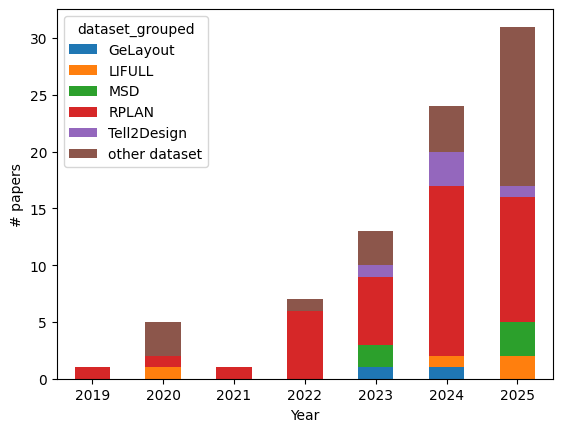

In [18]:
def merge_datasets(x):
    groups = ["LIFULL", "RPLAN", "GeLayout", "MSD", "Tell2Design"]
    return x if x in groups else "other dataset"

dataset_exploded["dataset_grouped"] = dataset_exploded["dataset"].apply(merge_datasets)

dataset_counts = (
    dataset_exploded
    .groupby(['Year', 'dataset_grouped'])
    .size()
    .unstack(fill_value=0)
)

ax = dataset_counts.plot(
    kind='bar',
    stacked=True,
    ylabel='# papers',
    # figsize=(12,6)
)
ax.tick_params(axis='x', rotation=0)

### GENERALIZABILITY

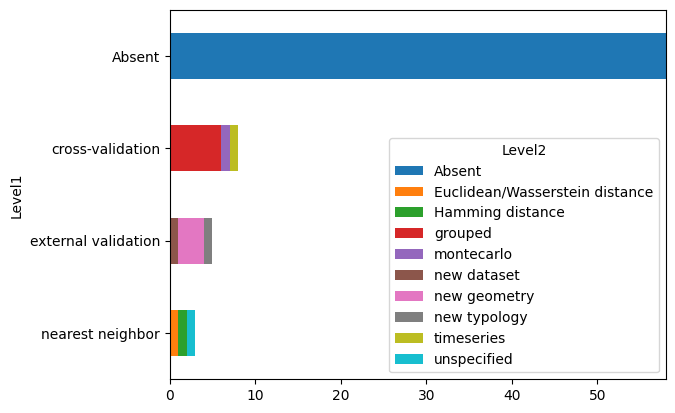

In [19]:
two_level_barh(df, "Generalizability")